### [GALT] Vežba 1: GAIA catalogue & basic statistics
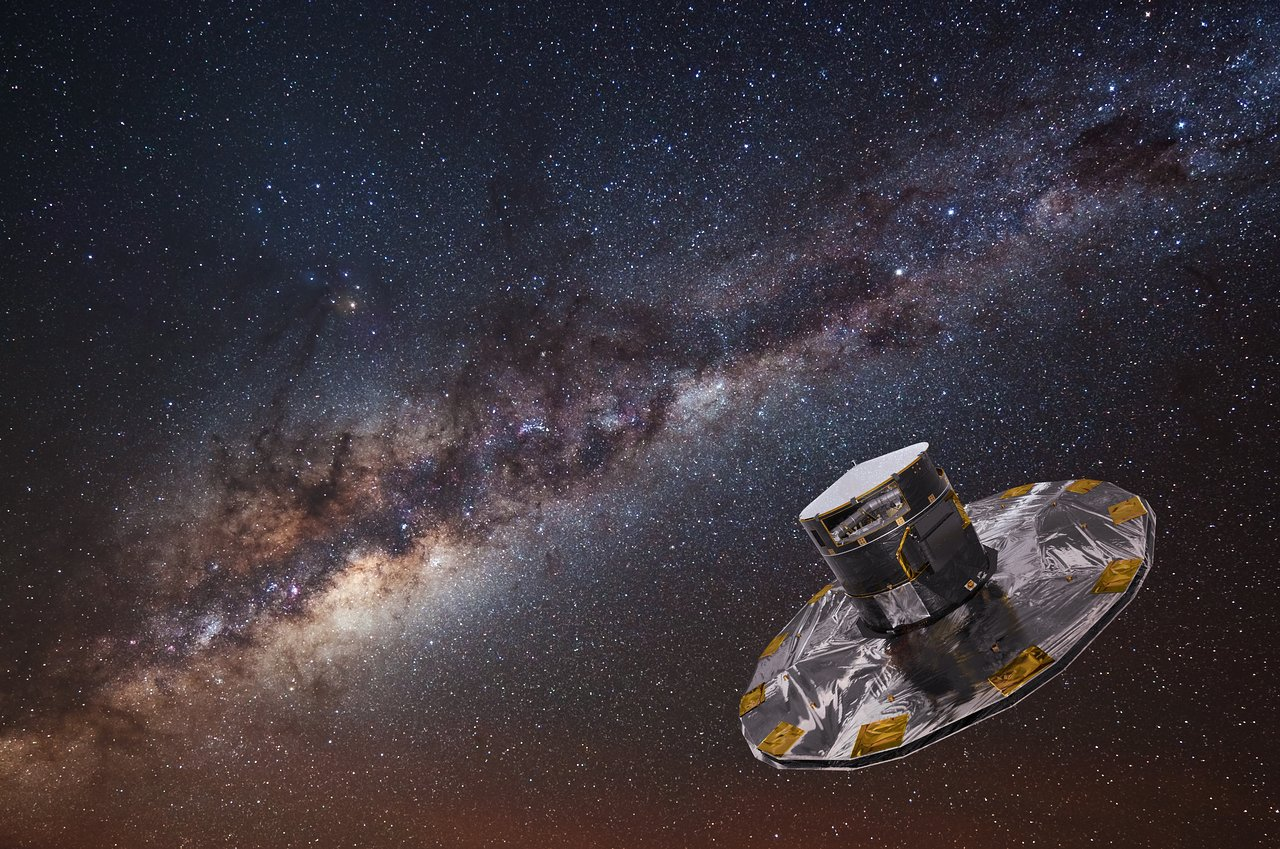

GAIA je svemirska astrometrijska misija Evropske svemirske agencije (ESA), čiji je osnovni cilj precizno merenje položaja i kretanja velikog broja astronomskih objekata. Lansirana je 19. decembra 2013. godine, a naučna posmatranja završena su 15. januara 2025. godine. Njeni podaci nastavljaju da se koriste za proučavanje strukture, kinematike i evolucije Mlečnog puta. Za razliku od teleskopa koji su prvenstveno usmereni na detaljno proučavanje pojedinačnih objekata, GAIA je osmišljena da sistematski posmatra veliki deo neba i stvori izuzetno obiman katalog astronomskih izvora.
Misija je omogućila da se proučavanje Galaksije pomeri sa zaključivanja na osnovu malog broja objekata na statističku analizu miliona i milijardi izvora.
Među najvažnijim rezultatima misije nalaze se:
- precizna merenja položaja zvezda na nebu;
- paralakse, na osnovu kojih možemo procenjivati udaljenosti;
- sopstvena kretanja zvezda po nebeskoj sferi;
- fotometrijska merenja u različitim opsezima talasnih dužina;
- radijalne brzine za deo posmatranih izvora;
- podaci o velikom broju dvojnih zvezda, promenljivih zvezda, jata i drugih astronomskih objekata.

Objavljivanje podataka odvijalo se u nekoliko izdanja. GAIA Data Release 3 (DR3) obuhvata približno 1,8 milijardi izvora, mada količina dostupnih podataka zavisi od vrste merenja i izabranog uzorka.

Podaci koje možemo da nađemo u katalogu su sledeći:

- _source_id_	- jedinstveni identifikator izvora u izdanju kataloga 
- _ra, dec_ - rektascenzija i deklinacija
- _l, b_ -	galaktička dužina i širina
- _parallax_ - paralaksa, u mililučnim sekundama (mas)
- _parallax_error_ - procena greške paralakse
- _pmra, pmdec_ - sopstvena kretanja u pravcu rektascenzije i deklinacije
- _phot_g_mean_mag_ - srednja prividna magnituda u GAIA \(G\) opsegu
- _bp_rp_ - indeks boje, razlika magnituda \(G_{\rm BP}-G_{\rm RP}\)
- _radial_velocity_ - radijalna brzina, dostupna samo za deo izvora

Ako želimo da preuzemo podatke, možemo da odemo na njihovu internet stranicu: https://www.cosmos.esa.int/web/gaia/data-release-3# gde možemo da koristimo _basic_ ili _advanced search_, u zavisnosti od toga šta nam je potrebno. Takođe, možemo direktno iz Python-a da komuniciramo sa bazom podataka, ali je za to neophodno da instaliramo __astroquery__ Python bibiloteku.

### <font color='yellow'>Ideja vežbe: Preuzimanje podataka iz različitih kataloga - za O zvezde iz GAIA DR3 kataloga, a za otvorena i globularna jata sa Vizier-a, i analiza datih podataka.</font>

#### <font color='red'>Na kraju svakog koraka, kada odradite ono što je bilo pitanje potrebno je iskomentarisati rešenje!</font>

Molim vas da ovu ćeliju koristite za sve biblioteke koje ćete naknadno da uvezete:

In [12]:
from astroquery.gaia import Gaia
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
from astroquery.vizier import Vizier
import astropy.units as u
from astropy.coordinates import Angle

Sada hoćemo da nađemo podatke za zvezde tipa O i sačuvamo u dva odvojena fajla njihove rektascenzije, deklinacije i paralakse.

In [8]:
# zvezde spektralnog tipa O (Teff >= 30,000 K)
# uzimamo samo 2000

o_query = """
SELECT TOP 3000
    g.source_id, 
    g.ra, 
    g.dec, 
    g.parallax, 
    g.parallax_over_error, 
    g.pmra, 
    g.pmdec, 
    g.phot_g_mean_mag, 
    g.bp_rp,
    a.teff_gspphot
FROM gaiadr3.gaia_source AS g
JOIN gaiadr3.astrophysical_parameters AS a ON g.source_id = a.source_id
WHERE a.teff_gspphot >= 30000
  AND g.parallax > 0
  AND g.parallax_over_error > 5
"""

job_o = Gaia.launch_job_async(o_query)
df_o = job_o.get_results().to_pandas()
df_o.to_csv("o_stars.csv", index=False)

INFO: Query finished. [astroquery.utils.tap.core]


In [9]:
# učitavam podatke za O: ra, dec i parallax
df_o = pd.read_csv("o_stars.csv")
o_data = df_o[["ra", "dec", "parallax"]]

Sada preuzimamo podatke za otvorena jata: Optically visible open clusters and Candidates (Dias+ 2002-2015)

https://vizier.cds.unistra.fr/viz-bin/VizieR-3?-source=B/ocl/clusters

In [10]:
# učitavamo celi katalog - Vizier ima svoj row limit
Vizier.ROW_LIMIT = -1

# globularna jata
globular_result = Vizier.get_catalogs("VII/202")
df_globular = globular_result[0].to_pandas()

# zadržavam samo podatke koji su mi potrebni
df_globular_clean = df_globular[["ID", "RAJ2000", "DEJ2000"]]
df_globular_clean.to_csv("globular_clusters_harris.csv", index=False)

# otvorena jata
open_result = Vizier.get_catalogs("B/ocl")
df_open = open_result[0].to_pandas()

# zadržavam samo podatke koji su mi potrebni
df_open_clean = df_open[["RAJ2000", "DEJ2000", "Dist"]]
df_open_clean.to_csv("open_clusters_dias.csv", index=False)

##### <font color="green">1.  Prikazati grafik DEC od RA, pri čemu razlicitim simbolima oznaciti otvorena zvezdana jata i O zvezde.</font>

Broj konvertovanih jata: 2167
RA opseg: 0.049999999999999996 359.9833333333333
DEC opseg: -83.42333333333333 85.255


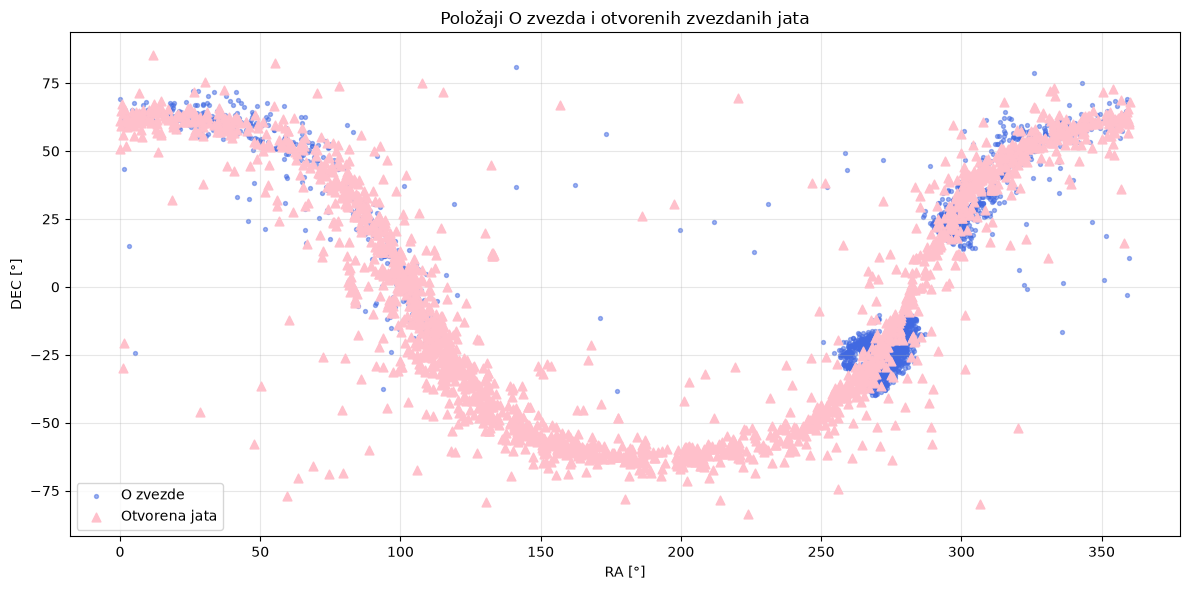

In [ ]:
from astropy.coordinates import SkyCoord

# konvertujem koordinate otvorenih jata u ekvatorijalni koordinatni sistem
# RA je zadata u satima, a DEC u stepenima
coords_open = SkyCoord(
    ra=df_open["RAJ2000"].astype(str).to_numpy(),
    dec=df_open["DEJ2000"].astype(str).to_numpy(),
    unit=(u.hourangle, u.deg),
    frame="icrs"
)

# pretvaram rektascenziju i deklinaciju u stepene
ra_open = coords_open.ra.deg
dec_open = coords_open.dec.deg



# Proveravam broj jata i opseg dobijenih koordinata
print("Broj konvertovanih jata:", len(ra_open))
print("RA opseg:", np.nanmin(ra_open), np.nanmax(ra_open))
print("DEC opseg:", np.nanmin(dec_open), np.nanmax(dec_open))



# Grafik
plt.figure(figsize=(12, 6))

plt.scatter(
    df_o["ra"], df_o["dec"],
    s=8, marker="o",
    color="royalblue", alpha=0.5,
    label="O zvezde"
)

plt.scatter(
    ra_open, dec_open,
    s=40, marker="^",
    color="pink",
    label="Otvorena jata",
    zorder=2
)

plt.xlabel("RA [°]")
plt.ylabel("DEC [°]")
plt.title("Položaji O zvezda i otvorenih zvezdanih jata")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


Položaji O zvezda i otvorenih zvezdanih jata u ekvatorijalnom koordinatnom sistemu:

Otvorena jata (roze): vidi se karakteristična raspodela duž diska Mlečnog puta. 

O zvezde (plavo): uglavnom koncentrisane duž galaktičke ravni, jer su to masivne, mlade zvezde koje nastaju u galaktičkom disku.

Veliki broj jata nalazi se u pojasu koji prati galaktičku ravan. Obe populacije pretežno koncentrisane duž pojasa koji odgovara projekciji galaktičkog diska na nebesku sferu. O zvezde su uglavnom vezane za galaktički disk zbog svoje kratke evolucije i nastanka u oblastima formiranja zvezda, dok otvorena jata pokazuju širu raspodelu. Uočeni oblik raspodele posledica je nagiba galaktičke ravni u odnosu na ekvatorijalnu ravan.

Razlike u raspodeli: otvorena jata su brojnija u uzorku i pokrivaju širi raspon deklinacija, dok su O zvezde koncentrisanije u određenim oblastima neba. Na raspodelu utiču i izbor uzorka i ograničenja posmatranja.

#### <font color="green">2. Odrediti udaljenosti do O zvezda. (Hint: Obratiti pažnju u kojoj jedinici je data paralaksa.)</font>

   parallax  distance_pc  distance_kpc
0  0.684036  1461.911048      1.461911
1  0.378823  2639.752590      2.639753
2  0.164906  6064.050551      6.064051
3  0.408472  2448.149775      2.448150
4  0.430449  2323.156261      2.323156
Srednja udaljenost [kpc]: 5.173653213395336
Medijalna udaljenost [kpc]: 5.261530313979506


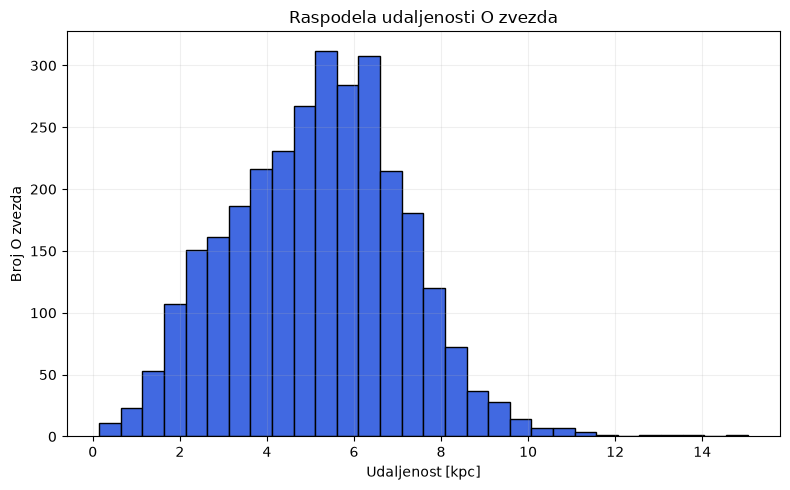

In [ ]:
#Udaljenost u parsecima
df_o["distance_pc"] = 1000 / df_o["parallax"]

# Udaljenost u kiloparsecima
df_o["distance_kpc"] = 1 / df_o["parallax"]

print(df_o[["parallax", "distance_pc", "distance_kpc"]].head())

print("Srednja udaljenost [kpc]:",
      df_o["distance_kpc"].mean())

print("Medijalna udaljenost [kpc]:",
      df_o["distance_kpc"].median())


# Grafik
plt.figure(figsize=(8, 5))

plt.hist(
    df_o["distance_kpc"].dropna(),
    bins=30, color="royalblue", edgecolor="black"
)

plt.xlabel("Udaljenost [kpc]")
plt.ylabel("Broj O zvezda")
plt.title("Raspodela udaljenosti O zvezda")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

Udaljenosti su procenjene invertovanjem izmerenih paralaksi. Selekcija sa parallax_over_error > 5 smanjuje uticaj velikih relativnih grešaka, ali dobijene vrednosti i dalje tumačiti kao procene, a ne savršenu tačnost.

#### <font color="green">3. Određivanje položaja severnog galaktičkog pola</font>

Fitovati podatke funkcijom (zajedno podatke za O zvezde i otvorena jata) koja predstavlja veliki krug na nebeskoj sferi:

$$ \tan(\mathrm{\delta}) = \sin(\mathrm{\alpha}-\mathrm{\alpha}_{\omega})\tan(i), $$

gde su parametri fita $\mathrm{\alpha}_{\omega}$ i $i$.

Položaj severnog galaktičkog pola određuje se pomoću relacija:

$$ \mathrm{\alpha}_{\mathrm{PNG}} = \mathrm{\alpha}_{\omega} - 6\,\mathrm{h},$$

$$ \mathrm{\delta}_{\mathrm{PNG}} = 90^\circ - i.$$

Na osnovu dobijenih parametara fita odrediti koordinate severnog galaktičkog pola.

Dobijene vrednosti uporediti sa usvojenim vrednostima za epohu J2000:

$$ i = 62.87^\circ,
\qquad \mathrm{\alpha}_{\omega} = 18^\mathrm{h}51^\mathrm{m}26^\mathrm{s}.$$

Na grafiku prikazati posmatrane podatke i teorijsku funkciju velikog kruga nebeske sfere, definisanu jednačinom iznad.


alpha_omega = 284.6135 deg
i = 61.4118 deg
RA severnog galaktičkog pola = 194.6135 deg
DEC severnog galaktičkog pola = 28.5882 deg


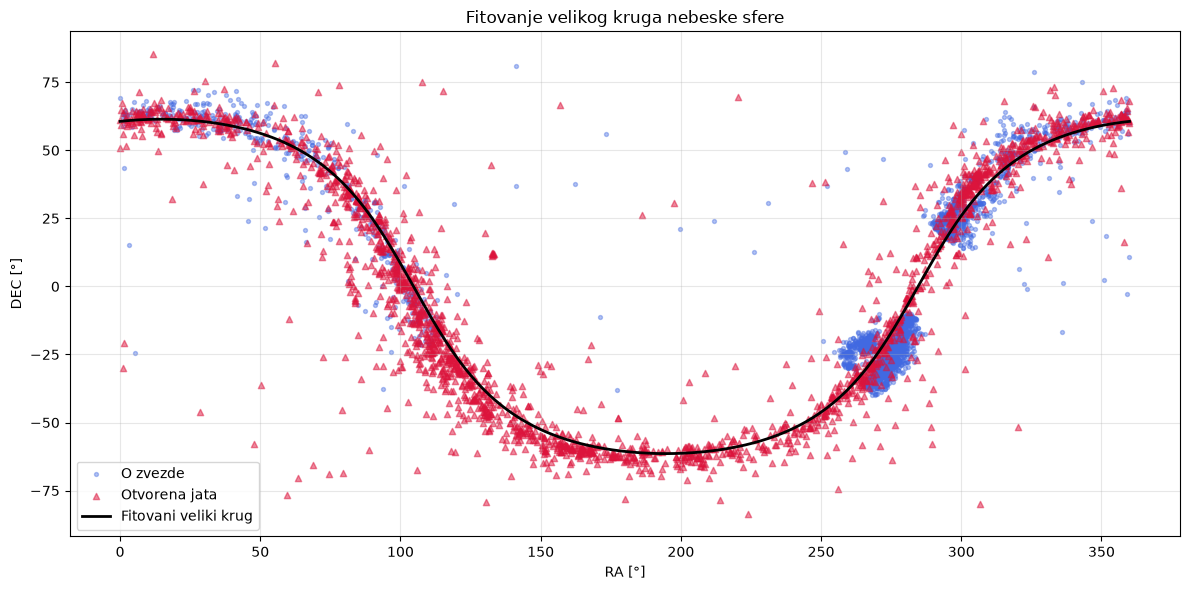

In [ ]:
from scipy.optimize import curve_fit

# spajanje koordinata O zvezda i otvorenih jata
ra_all = np.concatenate([ra_o, ra_open])
dec_all = np.concatenate([dec_o, dec_open])

# uklanjanje neispravnih koordinata
mask = (
    np.isfinite(ra_all) &
    np.isfinite(dec_all) &
    (dec_all > -90) &
    (dec_all < 90)
)

ra_all = ra_all[mask]
dec_all = dec_all[mask]

# pretvaranje u radijane
alpha = np.deg2rad(ra_all)
delta = np.deg2rad(dec_all)


# model velikog kruga
def veliki_krug(alpha, alpha_omega, i):
    return np.arctan(
        np.sin(alpha - alpha_omega) * np.tan(i)
    )


# Početne vrednosti iz zadatka
alpha_omega_0 = np.deg2rad(282.858333)
i_0 = np.deg2rad(62.87)

# Fitovanje
popt, pcov = curve_fit(
    veliki_krug,
    alpha,
    delta,
    p0=[alpha_omega_0, i_0],
    bounds=(
        [0, np.deg2rad(1)],
        [2 * np.pi, np.deg2rad(89)]
    ),
    maxfev=20000
)

alpha_omega_fit, i_fit = popt

# Koordinate severnog galaktičkog pola
ra_png = (np.rad2deg(alpha_omega_fit) - 90) % 360
dec_png = 90 - np.rad2deg(i_fit)

print(f"alpha_omega = {np.rad2deg(alpha_omega_fit):.4f} deg")
print(f"i = {np.rad2deg(i_fit):.4f} deg")
print(f"RA severnog galaktičkog pola = {ra_png:.4f} deg")
print(f"DEC severnog galaktičkog pola = {dec_png:.4f} deg")



#Grafik
ra_curve = np.linspace(0, 360, 1000)
dec_curve = np.rad2deg(
    veliki_krug(
        np.deg2rad(ra_curve),
        alpha_omega_fit,
        i_fit
    )
)

plt.figure(figsize=(12, 6))

plt.scatter(
    ra_o, dec_o,
    s=8, color="royalblue", alpha=0.4,
    label="O zvezde"
)

plt.scatter(
    ra_open, dec_open,
    s=20, marker="^", color="crimson", alpha=0.5,
    label="Otvorena jata"
)

plt.plot(
    ra_curve, dec_curve,
    color="black", linewidth=2,
    label="Fitovani veliki krug"
)

plt.xlabel("RA [°]")
plt.ylabel("DEC [°]")
plt.title("Fitovanje velikog kruga nebeske sfere")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Fitovanjem položaja O zvezda i otvorenih jata određeni su parametri velikog kruga koji predstavlja projekciju galaktičke ravni na nebesku sferu. Iz parametara fitovanja dobija se procena položaja severnog galaktičkog pola, koja se upoređuje sa referentnim vrednostima za J2000.

Dobijene vrednosti su:

RA = 194° 36' 49"

DEC = 28° 35' 18"

alpha_omega = 18h 58m 27s;         Referentno = 18h 51m 26s  - dakle, odstupanje od oko 7 minuta

i = 61° 24' 42";                   Referentno = 62° 52' 12"  - odstupanje od 87 lučnih minuta

Ova odstupanja od referentnih vrednosti (oba iznose oko 1 do 2 stepena) nisu drastično velika za ovu situaciju, ali na to najverovatnije utiče različita osetljivost instrumenata na greške, izbor kataloga, različite populacije objekata i sl.

#### <font color="green">4. Izračunati galaktičke koordinate l i b za globularna jata. (Možete npr. koristiti funkciju SkyCoord.)</font>

         ID     RAJ2000    DEJ2000
0   NGC 104  00 24 05.2  -72 04 51
1   NGC 288  00 52 47.5  -26 35 24
2   NGC 362  01 03 14.3  -70 50 54
3  NGC 1261  03 12 15.3  -55 13 01
4     Pal 1  03 33 23.0  +79 34 50
         ID           l          b
0   NGC 104  305.895746 -44.889687
1   NGC 288  152.298408 -89.382849
2   NGC 362  301.532861 -46.247850
3  NGC 1261  270.541630 -52.125765
4     Pal 1  130.067030  19.029031


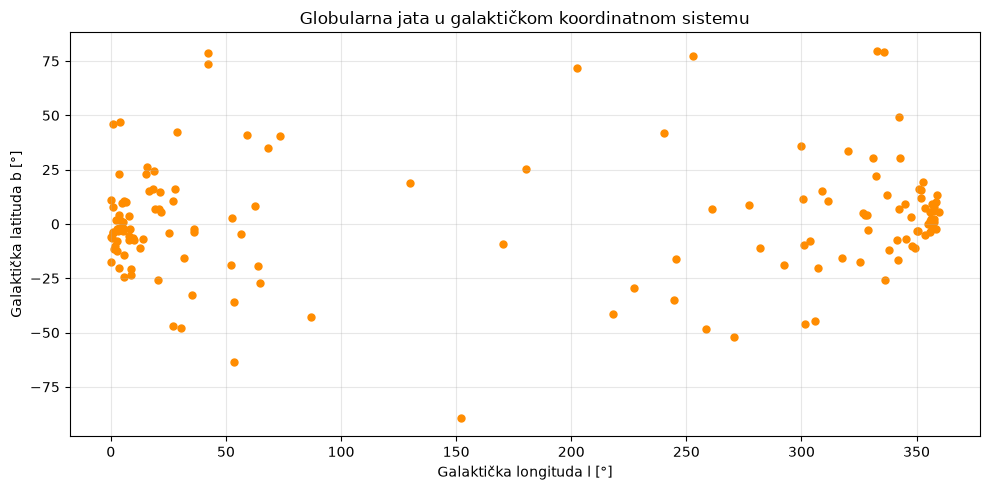

In [ ]:
# provera podataka
print(df_globular_clean.head())

# Pretpostavljam da su RAJ2000 i DEJ2000 u tekstualnom formatu sati/minuti/sekunde i stepeni
coords_globular = SkyCoord(
    ra=df_globular_clean["RAJ2000"].astype(str).to_numpy(),
    dec=df_globular_clean["DEJ2000"].astype(str).to_numpy(),
    unit=(u.hourangle, u.deg),
    frame="icrs"
)

# Galaktičke koordinate
df_globular_clean["l"] = coords_globular.galactic.l.deg
df_globular_clean["b"] = coords_globular.galactic.b.deg

print(df_globular_clean[["ID", "l", "b"]].head())

df_globular_clean.to_csv(
    "globular_clusters_galactic.csv",
    index=False
)


#Grafik
plt.figure(figsize=(10, 5))

plt.scatter(
    df_globular_clean["l"],
    df_globular_clean["b"],
    color="darkorange",
    s=25
)

plt.xlabel("Galaktička longitudа l [°]")
plt.ylabel("Galaktička latituda b [°]")
plt.title("Globularna jata u galaktičkom koordinatnom sistemu")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Ovde je izvršena transformacija ekvatorijalnih koordinata globularnih jata (rektascenzije RA i deklinacije DEC) u galaktičke koordinate (galaktičku longitudu l i galaktičku latitudu b). Za transformaciju je korišćena funkcija SkyCoord  iz Astropy pateka. Za razliku od ekvatorijalnog sistema, koji je definisan u odnosu na Zemljin ekvator, galaktički sistem je prilagođen ravni i orijentaciji Galaksije. Dobijene koordinate zato omogućavaju da se ispita koliko su globularna jata koncentrisana prema galaktičkom centru i koliko odstupaju od galaktičke ravni. Grafik prikazuje tu koncentraciju.


#### <font color="green">5. Galaktička latituda centra prividne raspodele.</font>
Odrediti galaktičku latitudu centra prividne raspodele globularnih jata. Kreirati prvo zone (pojase) jednakih površina na nebeskoj sferi, njih 10. Površina omotača jednog pojasa je  $2\pi h$, kako je $R=1$ za nebesku sferu. Kako nas zanima da izdelimo nebesku sferu na 10 zona, da je površina jednog omotača zapravo deseti deo površine cele nebeske sfere =>  $2\pi h=0.4\pi$, pa je visina $h = 0.2$, odnosno kako koristimo galaktički koordinatni sistem, prva zona od galaktičkog ekvatora $(b = 0)$ ide do $b = arcsin(0.2)$, kako je $R = 1$, a $sin(b) = h$ (vertikalna visina u odnosu na galaktički ekvator). Za granice zona imamo $b_j = arcsin(0.2(j-6))$, $j = 1, 2, 3, ..., 10$. Na sličan način se mogu naći galaktičke latitude koje odgovaraju centru pojasa, $b_{jc} = arcsin(0.2(j-6) + 0.1)$, $j = 1, 2, 3, ..., 10$. Zapravo, pravi se histogram po b, odnosno broje se objekti u konkretnim zonama. Grafički predstaviti histogram po galaktičkoj latitudi. Galaktička latituda maksimuma raspodele se može naći kao srednja vrednost tako grupisanih posmatranja:
$$b_{max} = \frac{\sum n_ib_i}{\sum n_i},$$
gde je $n_i$ broj zvezda u zoni čija je centralna galaktička latituda $b_i$. Proceniti  $b_{max}$ i za podelu od 20 zona. Koliko očekujemo da je  $b_{max}$, a kolika je računata vrednost?

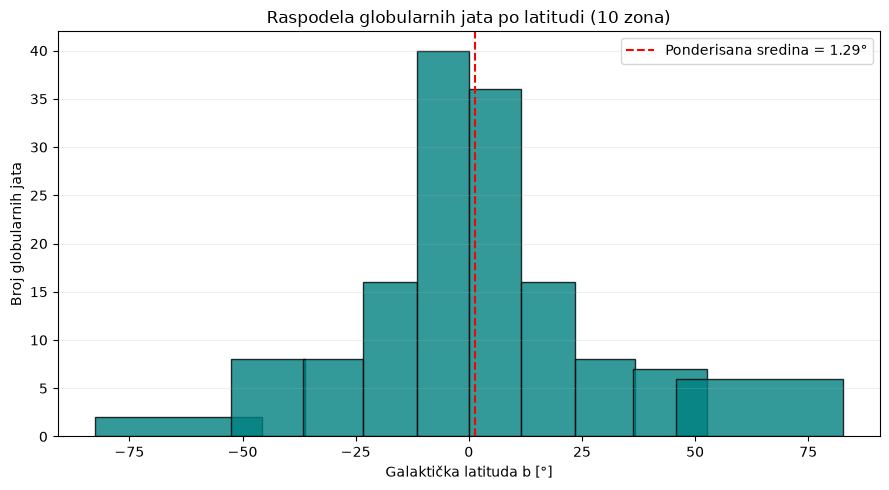

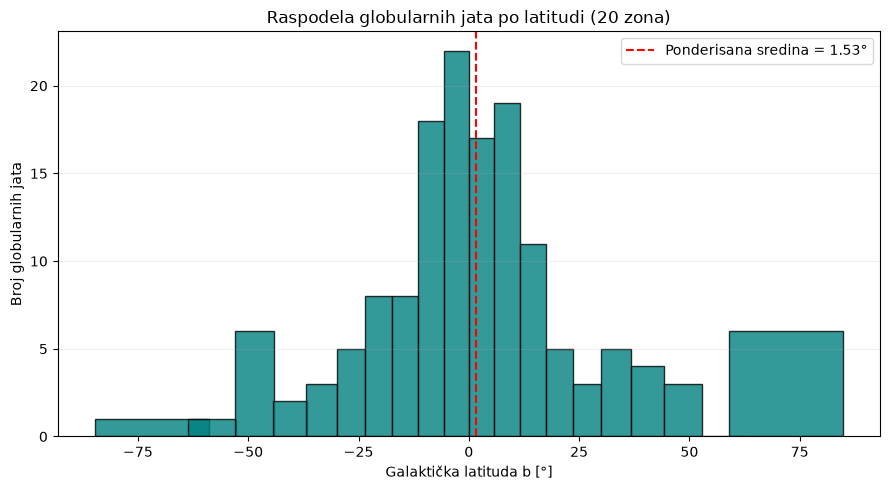

b za 10 zona: 1.287°
b za 20 zona: 1.535°


In [ ]:
def analiza_latitude(b_podaci, N, prikazi=True):

    # Uklanjanje nedostajućih vrednosti
    b_podaci = np.asarray(b_podaci, dtype=float)
    b_podaci = b_podaci[np.isfinite(b_podaci)]

    # Granice zona: jednake površine na sferi
    sin_granice = np.linspace(-1, 1, N + 1)
    granice = np.rad2deg(np.arcsin(sin_granice))

    #Centri zona u sin(b) i konverzija u stepene nakon toga
    sin_centri = (
        sin_granice[:-1] + sin_granice[1:]
    ) / 2

    centri = np.rad2deg(np.arcsin(sin_centri))

    # histogram broja jata po zonama
    brojevi, _ = np.histogram(
        b_podaci,
        bins=granice
    )

    # Ponderisana srednja latituda
    b_centar = np.sum(brojevi * centri) / np.sum(brojevi)

    if prikazi:
        plt.figure(figsize=(9, 5))

        plt.bar(
            centri,
            brojevi,
            width=np.diff(granice),
            color="teal",
            edgecolor="black",
            alpha=0.8
        )

        plt.axvline(
            b_centar,
            color="red",
            linestyle="--",
            label=f"Ponderisana sredina = {b_centar:.2f}°"
        )

        plt.xlabel("Galaktička latituda b [°]")
        plt.ylabel("Broj globularnih jata")
        plt.title(f"Raspodela globularnih jata po latitudi ({N} zona)")
        plt.legend()
        plt.grid(axis="y", alpha=0.2)
        plt.tight_layout()
        plt.show()

    return b_centar, brojevi, granice, centri


b10, n10, granice10, centri10 = analiza_latitude(
    df_globular_clean["b"], 10
)

b20, n20, granice20, centri20 = analiza_latitude(
    df_globular_clean["b"], 20
)

print(f"b za 10 zona: {b10:.3f}°")
print(f"b za 20 zona: {b20:.3f}°")

Očekivana vrednost b_max je ≈ 0°. Rezultati b_10 = 1.287° i b_20 = 1.535° su relativno blizu te očekivane vrednosti. 
Ako bi raspodela globularnih jata bila potpuno simetrična u odnosu na tu ravan, onda bi procenjeni centar raspodele bude na b = 0°, ali stvarna raspodela jata svakako nije savršeno simetrična. Broj jata iznad i ispod galaktičke ravni može da se razlikuje zbog stvarne prostorne raspodele, selekcionih efekata i nepotpunosti kataloga.

Razlika (mala) rezultata kod b_10 i b_20 pokazuje da rezultat donekle zavisi od izbora broja zona.

#### <font color="green">6. Galaktička longituda centra prividne raspodele, slično kao prethodno.</font>

#### <font color="green">7. Ako pretpostavimo da je centar prividne raspodele globularnih jata upravo centar naše galaksije, kolike su onda l i b galaktičkog centra (koliko očekujemo i koje vrednosti su izračunate)? Kolike su onda RA i DEC za J2000, središta naše galaksije (uporediti sa koordinatama Sag A*).</font>